# Przejazdy High Volume FHV (Uber, Lyft) w Nowym Jorku - lipiec i sierpień 2026

**Problem badawczy.** Jak wygląda rynek przewozów zamawianych przez aplikacje w Nowym Jorku?
Interesuje nas: udział przewoźników i ich model cenowy (jaką część opłaty dostaje kierowca),
kiedy w ciągu tygodnia i doby jest największy popyt i jak wpływa on na czas oczekiwania i prędkość,
od czego zależy cena przejazdu, kto i kiedy daje napiwki oraz którędy jeździ się najczęściej.

**Źródło danych.** NYC Taxi & Limousine Commission (TLC) - *TLC Trip Record Data*,
zbiór **High Volume For-Hire Vehicle (HVFHV) Trip Records** (przewoźnicy obsługujący > 10 000 przejazdów dziennie).

* strona zbioru: <https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page>
* pliki: `fhvhv_tripdata_2026-07.parquet`, `fhvhv_tripdata_2026-08.parquet`, pobierane z
  <https://d37ci6vzurychx.cloudfront.net/trip-data/>
* słownik danych: <https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_hvfhs.pdf>
* słownik stref (Taxi Zones): <https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv>

Zainstalowanie wymaganych bibliotek

```bash
pip install -r requirements
docker compose up -d
```

In [88]:
from pathlib import Path
import time
import urllib.request

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from bson import BSON
from pymongo import MongoClient, ASCENDING

DATA_DIR = Path(".")
MONTHS = ["2026-07", "2026-08"]
TLC_BASE_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data"
SOURCE_FILES = [DATA_DIR / f"fhvhv_tripdata_{m}.parquet" for m in MONTHS]
MERGED_FILE = DATA_DIR / "fhvhv_tripdata_2026-07_08.parquet"
ZONES_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
ZONES_FILE = DATA_DIR / "taxi_zone_lookup.csv"

MONGO_URI = "mongodb://localhost:27017"
DB_NAME = "nyc_taxi"
TRIPS = "fhvhv_trips"
QUALITY = "import_quality"

TARGET_DATA_GB = 5.5
REIMPORT = False
BATCH_ROWS = 1_000_000
INSERT_CHUNK = 20_000
RANDOM_SEED = 42

PERIOD_START = pd.Timestamp("2026-07-01")
PERIOD_END = pd.Timestamp("2026-09-01")
GIB = 1024 ** 3

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
PROVIDER_COLORS = {"Uber": SERIES[0], "Lyft": SERIES[1], "Via": SERIES[2], "Juno": SERIES[3]}
MONTH_COLORS = {"2026-07": SERIES[0], "2026-08": SERIES[1]}
BLUES = sns.blend_palette(["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"], as_cmap=True)
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#b5b4ae", "grid.color": "#e6e5e0", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "figure.dpi": 110,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 50)

## 1. Pobranie danych i połączenie plików miesięcznych w jeden plik Parquet

In [89]:
def download_file(url, target, chunk_size=8 * 1024 * 1024):
    part = target.with_suffix(target.suffix + ".part")
    t0 = time.time()
    with urllib.request.urlopen(url) as response, open(part, "wb") as out:
        total = int(response.headers.get("Content-Length", 0))
        done, next_report = 0, 0.1
        while chunk := response.read(chunk_size):
            out.write(chunk)
            done += len(chunk)
            if total and done / total >= next_report:
                print(f"  {target.name}: {done / total:4.0%} ({done / 1024**2:,.0f} MiB)")
                next_report += 0.1
    if total and part.stat().st_size != total:
        part.unlink()
        raise IOError(f"Niepełne pobranie {url}: {done} z {total} bajtów")
    part.replace(target)
    print(f"Pobrano {target.name} ({target.stat().st_size / 1024**2:,.0f} MiB) w {time.time() - t0:.0f} s")


def merge_parquet(sources, target):
    schema = pq.ParquetFile(sources[0]).schema_arrow
    for src in sources[1:]:
        other = pq.ParquetFile(src).schema_arrow
        if not other.equals(schema):
            print(f"Uwaga: schemat {src.name} różni się od {sources[0].name} - kolumny zostaną rzutowane.")
    tmp = target.with_suffix(".parquet.tmp")
    t0 = time.time()
    with pq.ParquetWriter(tmp, schema, compression="zstd") as writer:
        for src in sources:
            pf = pq.ParquetFile(src)
            for i in range(pf.num_row_groups):
                writer.write_table(pf.read_row_group(i).select(schema.names).cast(schema))
            print(f"  dopisano {src.name}: {pf.metadata.num_rows:,} wierszy")
    tmp.replace(target)
    print(f"Zapisano {target.name} w {time.time() - t0:.0f} s")


if MERGED_FILE.exists():
    print(f"Plik {MERGED_FILE.name} już istnieje - pomijam scalanie.")
else:
    for month, path in zip(MONTHS, SOURCE_FILES):
        if path.exists():
            print(f"Plik {path.name} już jest na dysku - pomijam pobieranie.")
        else:
            download_file(f"{TLC_BASE_URL}/{path.name}", path)
    merge_parquet(SOURCE_FILES, MERGED_FILE)

merged = pq.ParquetFile(MERGED_FILE)
source_rows = {f.name: pq.ParquetFile(f).metadata.num_rows for f in SOURCE_FILES if f.exists()}
print(f"Scalony plik: {merged.metadata.num_rows:,} wierszy, {merged.num_row_groups} grup wierszy, "
      f"{MERGED_FILE.stat().st_size / GIB:.2f} GiB")
if source_rows:
    assert merged.metadata.num_rows == sum(source_rows.values()), "Liczba wierszy nie zgadza się ze źródłami!"
    print("Kontrola: liczba wierszy = suma plików źródłowych", source_rows)

Plik fhvhv_tripdata_2026-07_08.parquet już istnieje - pomijam scalanie.
Scalony plik: 41,414,729 wierszy, 40 grup wierszy, 0.93 GiB
Kontrola: liczba wierszy = suma plików źródłowych {'fhvhv_tripdata_2026-07.parquet': 20921249, 'fhvhv_tripdata_2026-08.parquet': 20493480}


## 2. Przegląd surowych danych

In [90]:
print(merged.schema_arrow)
merged.read_row_group(0).slice(0, 5).to_pandas().T

hvfhs_license_num: large_string
dispatching_base_num: large_string
originating_base_num: large_string
request_datetime: timestamp[us]
on_scene_datetime: timestamp[us]
pickup_datetime: timestamp[us]
dropoff_datetime: timestamp[us]
PULocationID: int32
DOLocationID: int32
trip_miles: double
trip_time: int64
base_passenger_fare: double
tolls: double
bcf: double
sales_tax: double
congestion_surcharge: double
airport_fee: double
tips: double
driver_pay: double
shared_request_flag: large_string
shared_match_flag: large_string
access_a_ride_flag: large_string
wav_request_flag: large_string
wav_match_flag: large_string
cbd_congestion_fee: double


,0,1,2,3,4
hvfhs_license_num,HV0003,HV0003,HV0003,HV0005,HV0005
dispatching_base_num,B03404,B03404,B03404,B03406,B03406
originating_base_num,B03404,B03404,B03404,NaN,NaN
request_datetime,2026-07-01 00:11:48,2026-06-30 23:49:45,2026-07-01 00:25:33,2026-07-01 00:04:29,2026-07-01 00:44:42
on_scene_datetime,2026-07-01 00:14:30,2026-07-01 00:04:16,2026-07-01 00:36:44,2026-07-01 00:08:38,2026-07-01 00:47:32
pickup_datetime,2026-07-01 00:19:26,2026-07-01 00:05:53,2026-07-01 00:37:22,2026-07-01 00:09:20,2026-07-01 00:50:16
dropoff_datetime,2026-07-01 00:45:06,2026-07-01 00:35:24,2026-07-01 01:00:57,2026-07-01 00:26:42,2026-07-01 00:58:39
PULocationID,211,114,7,74,262
DOLocationID,236,7,63,262,141
trip_miles,4.65,6.47,12.95,2.26,1.58


In [91]:
def null_counts(pf):
    counts = dict.fromkeys(pf.schema_arrow.names, 0)
    for rg in range(pf.num_row_groups):
        meta = pf.metadata.row_group(rg)
        for c in range(meta.num_columns):
            col = meta.column(c)
            if col.statistics is not None and col.statistics.has_null_count:
                counts[col.path_in_schema] += col.statistics.null_count
    return pd.Series(counts)

nulls = null_counts(merged)
raw_overview = pd.DataFrame({
    "typ": [str(f.type) for f in merged.schema_arrow],
    "braki": nulls.values,
    "braki_%": nulls.values / merged.metadata.num_rows * 100,
}, index=nulls.index)
raw_overview

,typ,braki,braki_%
hvfhs_license_num,large_string,0,0.00
dispatching_base_num,large_string,0,0.00
originating_base_num,large_string,11351744,27.41
request_datetime,timestamp[us],0,0.00
on_scene_datetime,timestamp[us],1,0.00
pickup_datetime,timestamp[us],0,0.00
dropoff_datetime,timestamp[us],0,0.00
PULocationID,int32,0,0.00
DOLocationID,int32,0,0.00
trip_miles,double,0,0.00


In [92]:
rng = np.random.default_rng(RANDOM_SEED)
sample_rgs = sorted(rng.choice(merged.num_row_groups, size=4, replace=False))
raw_sample = pa.concat_tables([merged.read_row_group(i) for i in sample_rgs]).to_pandas()
raw_sample = raw_sample.sample(n=min(500_000, len(raw_sample)), random_state=RANDOM_SEED)
raw_sample.describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,min,1%,50%,99%,max,std
request_datetime,500000,2026-07-30 12:07:16.763022,2026-07-05 15:18:18,2026-07-05 17:45:24.970000,2026-08-08 16:09:31.500000,2026-08-16 11:47:18.010000,2026-08-16 14:00:00,NaN
on_scene_datetime,500000,2026-07-30 12:11:44.465549,2026-07-05 15:38:48,2026-07-05 17:49:05,2026-08-08 16:14:16.500000,2026-08-16 11:50:52.030000,2026-08-16 13:59:56,NaN
pickup_datetime,500000,2026-07-30 12:12:50.441972,2026-07-05 16:00:03,2026-07-05 17:50:15.990000,2026-08-08 16:15:21.500000,2026-08-16 11:52:07.010000,2026-08-16 13:59:56,NaN
dropoff_datetime,500000,2026-07-30 12:31:39.652888,2026-07-05 16:04:52,2026-07-05 18:08:16,2026-08-08 16:34:58,2026-08-16 12:09:15.010000,2026-08-16 15:25:40,NaN
PULocationID,"500,000.00",136.68,2.00,7.00,138.00,261.00,265.00,74.68
DOLocationID,"500,000.00",140.93,1.00,4.00,139.00,265.00,265.00,78.49
trip_miles,"500,000.00",5.00,0.00,0.46,2.95,26.82,"1,431.47",6.34
trip_time,"500,000.00","1,134.67",1.00,183.00,927.00,"3,957.00","41,523.00",810.96
base_passenger_fare,"500,000.00",26.17,-30.24,5.31,18.80,123.30,962.52,24.89
tolls,"500,000.00",1.12,0.00,0.00,0.00,16.79,61.35,3.71


Po wstępnym przejrzeniu danych uwagę przykuwają: ujemne opłaty, które pewnie świadczą o zwrotach lub korektach, czas oraz przejazdy ktore wynoszą 0, bardzo długie kursy, niestiniejące bądź występujące poza obszarem Nowego Jorku strefy, braki w kilku kolumnach.

## 3. Słownik stref (Taxi Zone Lookup)

Do zmapowania `PULocationID` / `DOLocationID` wykorzystano numery stref taksówkowych przechowywanych w pliku słownika na oficjalnej stronie. Dodatkowo wydzielono z nich nazwe dzielnicy oraz strefy.

In [93]:
if not ZONES_FILE.exists():
    urllib.request.urlretrieve(ZONES_URL, ZONES_FILE)
    print("Pobrano", ZONES_FILE.name)
zones = pd.read_csv(ZONES_FILE).set_index("LocationID")
print(f"{len(zones)} stref; dzielnice: {sorted(zones['Borough'].dropna().unique())}")
zones.head()

265 stref; dzielnice: ['Bronx', 'Brooklyn', 'EWR', 'Manhattan', 'Queens', 'Staten Island', 'Unknown']


,Borough,Zone,service_zone
LocationID,,,
1,EWR,Newark Airport,EWR
2,Queens,Jamaica Bay,Boro Zone
3,Bronx,Allerton/Pelham Gardens,Boro Zone
4,Manhattan,Alphabet City,Yellow Zone
5,Staten Island,Arden Heights,Boro Zone


## 4. Czyszczenie, walidacja i import do MongoDB

**Walidacja - rekord odrzucamy, jeśli:**
Usunieto wiersze, które:
- mają braki w kolumnach `request_datetime`, `pickup_datetime` lub `dropoff_datetime`, ponieważ tych danych nie można uzupełnić
- mają datę odbioru pasażera poza 1.07-31.08.2026, ponieważ dane powinny pochodzić tylko z lipca oraz sierpnia 2026 roku
- w kolumnie `dropoff_datetime` mają wcześniejszą datę aniżeli w kolumnie `pickup_datetime`, taka sytuacja nie ma prawa wystąpić
- w kolumnie `pickup_datetime` mają wcześniejszą datę aniżeli w kolumnie `request_datetime`, taka sytuacja nie ma prawa wystąpić
- mają czas przejazdu krótszy od 60 sekund albo dłuższy od 4 godzin, są to anomalie, które zaburzą statystyki
- mają przejechany dystans mniejszy od 0 mil albo większy od 150 mil, są to anomalie, które zaburzą statystyki
- mają oplatę bazową pasażera mniejszą od 0 USD albo większą od 1000 USD, są to anomalie, które zaburzą statystyki
- w kolumnie `driver_pay` mają wartości poniżej 0, ponieważ nie można wypłacić kierowcy ujemnej wartości
- mają wszystkie skladowe do końcowego kosztu ujemne tzn. ujemne napiwki opłaty drogowe lub inne dopłaty, ponieważ takie sytuacje nie powinny występować
- mają nieznaną strefę bądź strefę poza Nowym Jorkiem, celem analizy jest obszar samego Nowego Jorku
- mają prędkość powyżej 80 mil na godzine, gdyż jest to najpewniej błąd pomiaru
- są duplikatami, ponieważ nie wnoszą żadnej nowej informacji

Jeden rekord może łamać kilka reguł - liczymy każde naruszenie oraz łączną liczbę odrzuconych.

Dodatkowo wykonano następujące transformacje:
- zamieniono wartości `Y/N` na `1/0`,
- kody licencji zmapowano na odpowiednich przewoźników,
- braki w poszczególnych opłatach wypełnionio zerami,
- dodano dzielnicę oraz strefę startu/końca przejazdu,
- utworzono pola pochodne, ułatwiające dalszą analizę:
    - `trip_minutes` - czas przejazdu w minutach,
    - `wait_minutes` - czas oczekiwania od zamówienia do odbioru w minutach,
    - `speed_mph` - prędkość w milach na godzine,
    - `total_fare` - całkowity koszt przejazdu (ze wszystkimi opłatami) bez napiwku,
    - `driver_share` - część opłaty bazowej jaką dostaje kierowca,
    - `tip_pct` - część opłaty bazowej jaką stanowi napiwek,
    - `month` - miesiąc przejazdu,
    - `pickup_hour` - godzina odbioru,
    - `pickup_dow` - dzień tygodnia odbioru podawany w wartościach od 1 do 7, gdzie 1 to poniedziałek,
    - `pickup_date` - data odbioru,
    - `is_airport_trip` - określa czy dany przejazd był wyprawą z/do lotniska.

Do bazy MongoDB trafia losowa próbka danych z całego zbioru tak aby osiągnęła rozmiar co najmniej 5GiB. Docelowa wartość usatwiona jest przez zmienną `TARGET_DATA_GB`.

In [94]:
PROVIDERS = {"HV0002": "Juno", "HV0003": "Uber", "HV0004": "Via", "HV0005": "Lyft"}
FLAG_COLS = {
    "shared_request_flag": "shared_request", "shared_match_flag": "shared_match",
    "access_a_ride_flag": "access_a_ride", "wav_request_flag": "wav_request", "wav_match_flag": "wav_match",
}
FEE_COLS = ["tolls", "bcf", "sales_tax", "congestion_surcharge", "airport_fee", "cbd_congestion_fee", "tips"]
AIRPORT_ZONES = {1, 132, 138} 
borough_map = zones["Borough"].to_dict()
zone_map = zones["Zone"].to_dict()


def validate(df):
    fee_neg = np.zeros(len(df), dtype=bool)
    for c in FEE_COLS:
        fee_neg |= (df[c] < 0).to_numpy()
    hours = df["trip_time"] / 3600
    speed = np.where(hours > 0, df["trip_miles"] / hours.where(hours > 0, 1), np.inf)
    rules = {
        "brak_czasu": df[["request_datetime", "pickup_datetime", "dropoff_datetime"]].isna().any(axis=1),
        "poza_okresem": (df["pickup_datetime"] < PERIOD_START) | (df["pickup_datetime"] >= PERIOD_END),
        "koniec_przed_startem": df["dropoff_datetime"] <= df["pickup_datetime"],
        "zamowienie_po_odbiorze": df["request_datetime"] > df["pickup_datetime"],
        "czas_przejazdu": (df["trip_time"] <= 60) | (df["trip_time"] > 4 * 3600),
        "dystans": (df["trip_miles"] <= 0) | (df["trip_miles"] > 150),
        "oplata": (df["base_passenger_fare"] <= 0) | (df["base_passenger_fare"] > 1000)
                  | df["base_passenger_fare"].isna(),
        "wynagrodzenie_kierowcy": (df["driver_pay"] < 0) | df["driver_pay"].isna(),
        "skladowe_ujemne": pd.Series(fee_neg, index=df.index),
        "nieznana_strefa": ~df["PULocationID"].between(1, 263) | ~df["DOLocationID"].between(1, 263),
        "predkosc": pd.Series(speed > 80, index=df.index),
        "duplikat": df.duplicated(),
    }
    return {k: v.fillna(False).to_numpy(dtype=bool) for k, v in rules.items()}


def transform(df):
    out = pd.DataFrame(index=df.index)
    out["provider"] = df["hvfhs_license_num"].map(PROVIDERS).fillna("Inny")
    out["license_num"] = df["hvfhs_license_num"]
    out["dispatching_base"] = df["dispatching_base_num"]
    for c in ["request_datetime", "pickup_datetime", "dropoff_datetime"]:
        out[c] = df[c]
    out["pu_location_id"] = df["PULocationID"].astype(int)
    out["do_location_id"] = df["DOLocationID"].astype(int)
    out["pu_borough"] = df["PULocationID"].map(borough_map)
    out["pu_zone"] = df["PULocationID"].map(zone_map)
    out["do_borough"] = df["DOLocationID"].map(borough_map)
    out["do_zone"] = df["DOLocationID"].map(zone_map)
    out["trip_miles"] = df["trip_miles"].round(2)
    out["trip_minutes"] = (df["trip_time"] / 60).round(2)
    out["wait_minutes"] = ((df["pickup_datetime"] - df["request_datetime"]).dt.total_seconds() / 60).round(2)
    out["speed_mph"] = (df["trip_miles"] / (df["trip_time"] / 3600)).round(2)
    out["base_passenger_fare"] = df["base_passenger_fare"]
    for c in FEE_COLS:
        out[c] = df[c].fillna(0.0)
    out["driver_pay"] = df["driver_pay"]
    out["total_fare"] = (df["base_passenger_fare"] + out[FEE_COLS[:-1]].sum(axis=1)).round(2)
    out["driver_share"] = (df["driver_pay"] / df["base_passenger_fare"]).round(4)
    out["tip_pct"] = (out["tips"] / df["base_passenger_fare"] * 100).round(2)
    out["fare_per_mile"] = (df["base_passenger_fare"] / df["trip_miles"]).round(2)
    for src, dst in FLAG_COLS.items():
        out[dst] = df[src].eq("Y")
    out["is_airport_trip"] = df["PULocationID"].isin(AIRPORT_ZONES) | df["DOLocationID"].isin(AIRPORT_ZONES)
    pickup = df["pickup_datetime"]
    out["month"] = pickup.dt.strftime("%Y-%m")
    out["pickup_date"] = pickup.dt.strftime("%Y-%m-%d")
    out["pickup_hour"] = pickup.dt.hour.astype(int)
    out["pickup_dow"] = (pickup.dt.dayofweek + 1).astype(int)
    return out


def to_documents(df):
    docs = df.to_dict("records")
    for col in df.columns[df.isna().any()]:
        for d in docs:
            if pd.isna(d[col]):
                d[col] = None
    return docs

In [95]:
client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5000)
print("MongoDB", client.server_info()["version"])
db = client[DB_NAME]
trips = db[TRIPS]

already = trips.estimated_document_count()
if REIMPORT or already == 0:
    trips.drop()
    db[QUALITY].drop()
    do_import = True
else:
    do_import = False
    print(f"Kolekcja {DB_NAME}.{TRIPS} zawiera już {already:,} dokumentów - pomijam import "
          "(ustaw REIMPORT = True, aby zaimportować ponownie).")

MongoDB 8.3.13
Kolekcja nyc_taxi.fhvhv_trips zawiera już 6,991,021 dokumentów - pomijam import (ustaw REIMPORT = True, aby zaimportować ponownie).


In [96]:
def run_import():
    rng = np.random.default_rng(RANDOM_SEED)
    total_rows = merged.metadata.num_rows
    rule_counts = None
    stats_rows = {"wczytane": 0, "odrzucone": 0, "czyste": 0, "zaimportowane": 0}
    fraction = None
    t0 = time.time()
    run_id = db[QUALITY].insert_one({"status": "in_progress", "created_at": pd.Timestamp.now().to_pydatetime()}).inserted_id

    for i, batch in enumerate(merged.iter_batches(batch_size=BATCH_ROWS)):
        df = batch.to_pandas()
        rules = validate(df)
        bad = np.logical_or.reduce(list(rules.values()))
        if rule_counts is None:
            rule_counts = dict.fromkeys(rules, 0)
        for k, v in rules.items():
            rule_counts[k] += int(v.sum())
        clean = transform(df.loc[~bad])
        stats_rows["wczytane"] += len(df)
        stats_rows["odrzucone"] += int(bad.sum())
        stats_rows["czyste"] += len(clean)

        if fraction is None:
            if TARGET_DATA_GB is None:
                fraction = 1.0
            else:
                probe = to_documents(clean.sample(n=min(5_000, len(clean)), random_state=RANDOM_SEED))
                avg_bson = np.mean([len(BSON.encode(d)) for d in probe]) + 17
                expected_clean = total_rows * len(clean) / len(df)
                fraction = min(1.0, TARGET_DATA_GB * GIB / avg_bson / expected_clean)
                print(f"Średni dokument ≈ {avg_bson:.0f} B, oczekiwane czyste rekordy ≈ {expected_clean:,.0f}, "
                      f"frakcja próbkowania = {fraction:.3f}")

        if fraction < 1.0:
            clean = clean.loc[rng.random(len(clean)) < fraction]
        docs = to_documents(clean)
        for start in range(0, len(docs), INSERT_CHUNK):
            trips.insert_many(docs[start:start + INSERT_CHUNK], ordered=False)
        stats_rows["zaimportowane"] += len(docs)
        print(f"partia {i + 1:>2}: wczytano {len(df):>9,}  odrzucono {int(bad.sum()):>7,}  "
              f"zaimportowano {len(docs):>8,}  | razem {stats_rows['zaimportowane']:>11,}  "
              f"({time.time() - t0:,.0f} s)")

    report = {
        "status": "zakonczony",
        "created_at": pd.Timestamp.now().to_pydatetime(),
        "source_file": MERGED_FILE.name,
        "sample_fraction": fraction,
        **stats_rows,
        "naruszenia_regul": rule_counts,
    }
    db[QUALITY].replace_one({"_id": run_id}, report)
    return report


if do_import:
    report = run_import()
else:
    report = db[QUALITY].find_one(sort=[("created_at", -1)])
    if report is None or report.get("status") == "in_progress":
        raise RuntimeError(
            f"Import do {DB_NAME}.{TRIPS} jest w toku albo został przerwany (brak zakończonego raportu "
            f"w kolekcji {QUALITY}). Poczekaj na koniec importu albo ustaw REIMPORT = True.")

trips.create_index([("pickup_datetime", ASCENDING)])
trips.create_index([("provider", ASCENDING), ("month", ASCENDING)])
trips.create_index([("pu_borough", ASCENDING)])
trips.create_index([("pickup_dow", ASCENDING), ("pickup_hour", ASCENDING)])
print("Indeksy:", list(trips.index_information()))

Indeksy: ['_id_', 'pickup_datetime_1', 'provider_1_month_1', 'pu_borough_1', 'pickup_dow_1_pickup_hour_1']


In [97]:
coll_stats = db.command("collStats", TRIPS)
print(f"Dokumenty w {DB_NAME}.{TRIPS}: {coll_stats['count']:,}")
print(f"Rozmiar danych:          {coll_stats['size'] / GIB:6.2f} GiB")
print(f"Rozmiar indeksów:           {coll_stats['totalIndexSize'] / GIB:6.2f} GiB")
print(f"Średni dokument: {coll_stats['avgObjSize']:,} B")
trips.find_one({}, {"_id": 0})

Dokumenty w nyc_taxi.fhvhv_trips: 6,991,021
Rozmiar danych:            5.50 GiB
Rozmiar indeksów:             0.24 GiB
Średni dokument: 845 B


{'provider': 'Lyft',
 'license_num': 'HV0005',
 'dispatching_base': 'B03406',
 'request_datetime': datetime.datetime(2026, 7, 1, 0, 44, 42),
 'pickup_datetime': datetime.datetime(2026, 7, 1, 0, 50, 16),
 'dropoff_datetime': datetime.datetime(2026, 7, 1, 0, 58, 39),
 'pu_location_id': 262,
 'do_location_id': 141,
 'pu_borough': 'Manhattan',
 'pu_zone': 'Yorkville East',
 'do_borough': 'Manhattan',
 'do_zone': 'Lenox Hill West',
 'trip_miles': 1.58,
 'trip_minutes': 9.12,
 'wait_minutes': 5.57,
 'speed_mph': 10.42,
 'base_passenger_fare': 11.9,
 'tolls': 0.0,
 'bcf': 0.22,
 'sales_tax': 0.79,
 'congestion_surcharge': 2.75,
 'airport_fee': 0.0,
 'cbd_congestion_fee': 0.0,
 'tips': 0.0,
 'driver_pay': 8.24,
 'total_fare': 15.66,
 'driver_share': 0.6924,
 'tip_pct': 0.0,
 'fare_per_mile': 7.51,
 'shared_request': False,
 'shared_match': False,
 'access_a_ride': False,
 'wav_request': False,
 'wav_match': False,
 'is_airport_trip': False,
 'month': '2026-07',
 'pickup_date': '2026-07-01',
 '

### 4.1. Raport jakości danych

Raport zapisany w kolekcji `import_quality`: ile rekordów odrzuciła każda reguła.

wczytane         41,414,729
odrzucone         2,410,020
czyste           39,004,709
zaimportowane     6,991,021
Odrzucono 5.82% rekordów; frakcja próbki zaimportowanej do MongoDB: 0.179


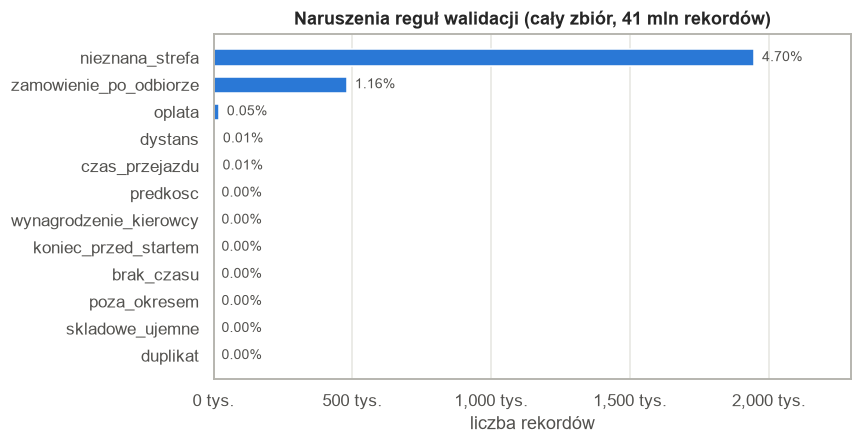

,liczba,%_wszystkich
nieznana_strefa,1946500,4.70
zamowienie_po_odbiorze,480089,1.16
oplata,19340,0.05
dystans,5171,0.01
czas_przejazdu,3946,0.01
predkosc,137,0.00
wynagrodzenie_kierowcy,6,0.00
koniec_przed_startem,2,0.00
brak_czasu,0,0.00
poza_okresem,0,0.00


In [98]:
quality = (pd.Series(report["naruszenia_regul"], name="liczba")
           .to_frame()
           .assign(**{"%_wszystkich": lambda d: d["liczba"] / report["wczytane"] * 100})
           .sort_values("liczba", ascending=False))
summary = pd.Series({k: report[k] for k in ["wczytane", "odrzucone", "czyste", "zaimportowane"]})
print(summary.map("{:,}".format).to_string())
print(f"Odrzucono {report['odrzucone'] / report['wczytane']:.2%} rekordów; "
      f"frakcja próbki zaimportowanej do MongoDB: {report['sample_fraction']:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
q = quality.sort_values("liczba")
ax.barh(q.index, q["liczba"], color=SERIES[0], height=0.6)
for y, (n, p) in enumerate(zip(q["liczba"], q["%_wszystkich"])):
    ax.text(n, y, f"  {p:.2f}%", va="center", fontsize=9, color="#52514e")
ax.set_title("Naruszenia reguł walidacji (cały zbiór, 41 mln rekordów)")
ax.set_xlabel("liczba rekordów")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f} tys."))
ax.grid(axis="y", visible=False)
ax.set_xlim(right=q["liczba"].max() * 1.18)
plt.tight_layout()
plt.show()
quality

## 5. Analizy statystyczne

Każda agregacja wykonywana jest na bazie danych poprzez metodę `agg`. Dodatkowo aby pobierać próbki statystyczne wykorzystano operator `$sample` na bazie, przekazywany przez metodę `sample_docs`.

In [99]:
def agg(pipeline, **kwargs):
    return pd.DataFrame(list(trips.aggregate(pipeline, allowDiskUse=True, **kwargs)))


def sample_docs(n, match=None, fields=()):
    pipeline = ([{"$match": match}] if match else []) + [
        {"$sample": {"size": n}},
        {"$project": {"_id": 0, **{f: 1 for f in fields}}},
    ]
    return agg(pipeline)

### 5.1. Udział przewoźników w rynku i podział opłaty między pasażera i kierowcę

In [100]:
providers = agg([
    {"$group": {
        "_id": {"provider": "$provider", "month": "$month"},
        "przejazdy": {"$sum": 1},
        "sr_oplata_bazowa": {"$avg": "$base_passenger_fare"},
        "mediana_oplaty": {"$median": {"input": "$base_passenger_fare", "method": "approximate"}},
        "sr_oplata_calkowita": {"$avg": "$total_fare"},
        "sr_wyplata_kierowcy": {"$avg": "$driver_pay"},
        "sr_udzial_kierowcy": {"$avg": "$driver_share"},
        "sr_dystans_mile": {"$avg": "$trip_miles"},
        "sr_oczekiwanie_min": {"$avg": "$wait_minutes"},
    }},
    {"$sort": {"_id.month": 1, "przejazdy": -1}},
])
providers = pd.concat([pd.json_normalize(providers["_id"]), providers.drop(columns="_id")], axis=1)
providers["udzial_w_rynku_%"] = providers["przejazdy"] / providers.groupby("month")["przejazdy"].transform("sum") * 100
providers

,provider,month,przejazdy,sr_oplata_bazowa,mediana_oplaty,sr_oplata_calkowita,sr_wyplata_kierowcy,sr_udzial_kierowcy,sr_dystans_mile,sr_oczekiwanie_min,udzial_w_rynku_%
0,Uber,2026-07,2571144,25.19,18.61,30.64,19.69,0.83,4.41,5.46,72.86
1,Lyft,2026-07,957979,23.83,18.30,28.49,17.76,0.75,4.06,5.20,27.14
2,Uber,2026-08,2503177,24.98,18.65,30.30,19.59,0.82,4.48,5.45,72.31
3,Lyft,2026-08,958721,23.37,17.99,27.82,17.62,0.75,4.07,5.13,27.69


Z tabeli można zaobserwować, że Uber miał ponad dwa razy więcej przejazdów aniżeli Lyft. Dodatkowo kierowcy Ubera zarabiali więcej aniżeli kierowcy Lyfta, jednocześnie Uber liczy sobie więcej za przejazd. Co więcej przejazdy Uberem były dłuższe i też się na nie dłużej czekało w porównaniu do przejazdów Lyft.

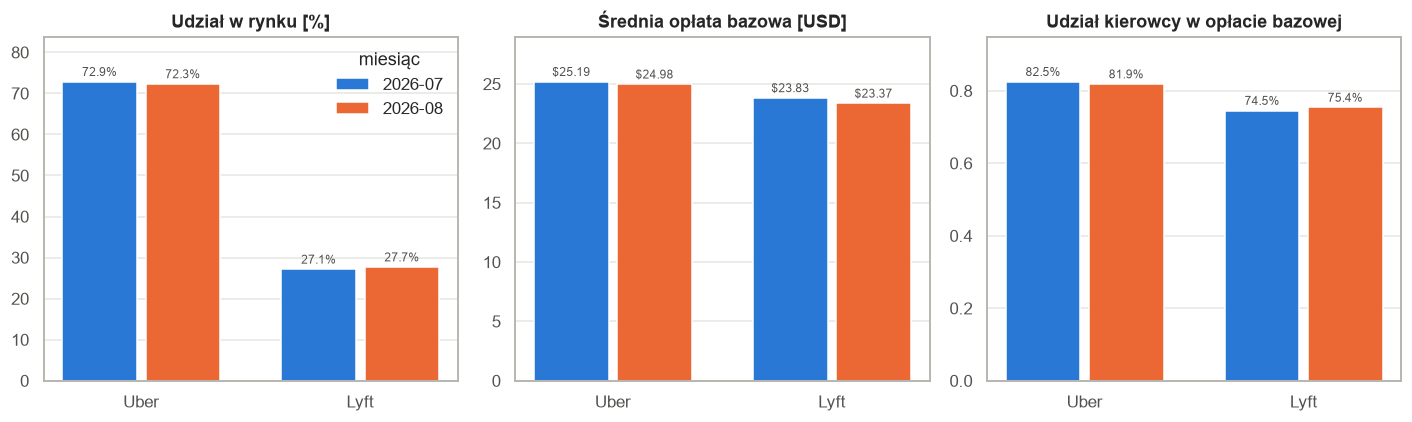

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
order = providers.groupby("provider")["przejazdy"].sum().sort_values(ascending=False).index
months = sorted(providers["month"].unique())
width = 0.38
x = np.arange(len(order))
metrics = [("udzial_w_rynku_%", "Udział w rynku [%]", "{:.1f}%"),
           ("sr_oplata_bazowa", "Średnia opłata bazowa [USD]", "${:.2f}"),
           ("sr_udzial_kierowcy", "Udział kierowcy w opłacie bazowej", "{:.1%}")]
for ax, (col, title, fmt) in zip(axes, metrics):
    for j, m in enumerate(months):
        vals = providers[providers["month"] == m].set_index("provider").reindex(order)[col]
        bars = ax.bar(x + (j - 0.5) * width, vals, width - 0.04, color=MONTH_COLORS[m], label=m)
        ax.bar_label(bars, labels=[fmt.format(v) for v in vals], fontsize=8, color="#52514e", padding=2)
    ax.set_xticks(x, order)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
axes[0].legend(title="miesiąc", frameon=False)
plt.tight_layout()
plt.show()

Na wykresach można zaobserwować przewagę Ubera nad Lyftem w kwestii udziału na rynku, dodatkowo ci dwaj przewoźnicy są jedynymi przewoźnikami w badanych miesiącach. Udział kierowcy w opłacie bazowej dla kierowcy Ubera jest w przedziale około od 82% do 83%, gdzie dla kierowcy Lyfta jest to już około od 74% do 75.5%. Średnio kierowca Ubera zarabia więcej niż kierowca Lyfta.

W celu sprawdzenia statystycznej istotności różnicy pomiędzy kolumnami `driver_share` oraz `fare_per_mile` w zależności od przewoźnika wykorzystano test Mann Whitneya wzbogaconego o korelacje rangowo-dwuseryjną w celu określenia mocy ewentualnego efektu. Poziom istotności dla testu wynosi $\alpha=0.05$

In [102]:
samples = {p: sample_docs(50_000, {"provider": p}, ["driver_share", "fare_per_mile"]) for p in ["Uber", "Lyft"]}
rows = []
for col in ["driver_share", "fare_per_mile"]:
    a, b = samples["Uber"][col], samples["Lyft"][col]
    u, p_val = stats.mannwhitneyu(a, b, alternative="two-sided")
    effect = 1 - 2 * u / (len(a) * len(b))
    rows.append({"zmienna": col, "U": u, "p_value": p_val, "efekt_rank_biserial": effect})
pd.DataFrame(rows).set_index("zmienna")

,U,p_value,efekt_rank_biserial
zmienna,,,
driver_share,"1,404,004,989.00",0.00,-0.12
fare_per_mile,"1,159,598,707.50",0.00,0.07


Test Manna-Whitneya daje p-value ≈ 0 dla obu zmiennych, a więc jest mniejszy od przyjętego poziomu istotności, co pozwala na odrzucenie hipotezy zerowej w obydwu przypadkach. Wpływ różnicy dla zmiennej `fare_per_mile` jest znikomy, natomiast dla zmiennej `driver_share` jest mały.

### 5.2. Popyt w ciągu tygodnia i doby, czas oczekiwania i prędkość

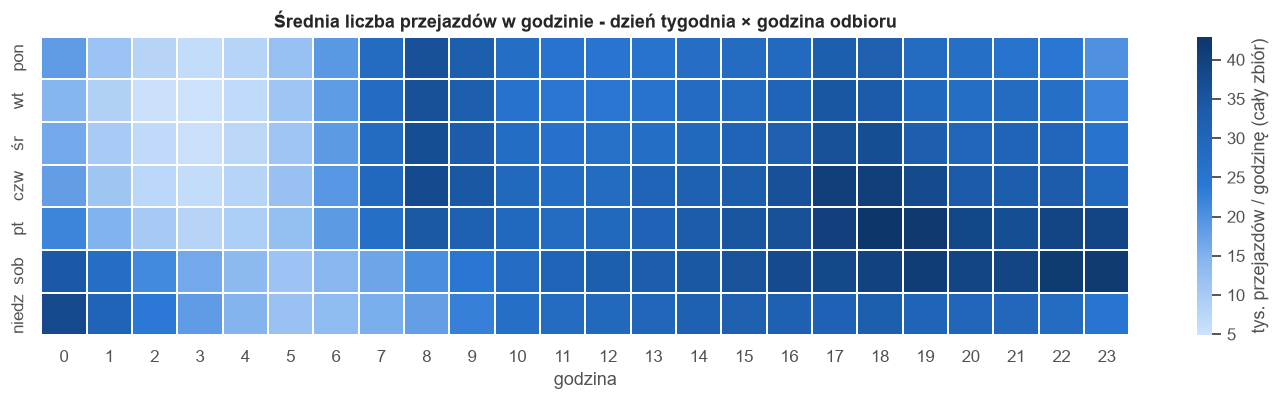

In [103]:
hourly = agg([
    {"$group": {
        "_id": {"dow": "$pickup_dow", "hour": "$pickup_hour"},
        "przejazdy": {"$sum": 1},
        "sr_oczekiwanie_min": {"$avg": "$wait_minutes"},
        "sr_predkosc_mph": {"$avg": "$speed_mph"},
    }},
])
hourly = pd.concat([pd.json_normalize(hourly["_id"]), hourly.drop(columns="_id")], axis=1)
DOW_NAMES = {1: "pon", 2: "wt", 3: "śr", 4: "czw", 5: "pt", 6: "sob", 7: "niedz"}
dow_days = pd.Series(pd.date_range(PERIOD_START, PERIOD_END - pd.Timedelta(days=1)).dayofweek + 1).value_counts()
hourly["przejazdy_na_dzien"] = hourly["przejazdy"] / hourly["dow"].map(dow_days) / report["sample_fraction"]
heat = hourly.pivot(index="dow", columns="hour", values="przejazdy_na_dzien").rename(index=DOW_NAMES)

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat / 1000, cmap=BLUES, ax=ax, linewidths=1, linecolor="white",
            cbar_kws={"label": "tys. przejazdów / godzinę (cały zbiór)"})
ax.set_title("Średnia liczba przejazdów w godzinie - dzień tygodnia × godzina odbioru")
ax.set_xlabel("godzina")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Na mapie ciepła można zaobserwować, że w dni robocze w godzinach porannych, czyli około 8, oraz popołudniowych, 17:00-18:00 występuje wzmożony ruch. W piątek i sobotę ruch utrzymuje się do późnej nocy. Co więcej, największy ruch przypada na noc z soboty na niedziele. Natomiast godziny poranne w weekendy charakteryzują się mniejszym ruchem w porównaniu do reszty tygodnia.

W celu sprawdzenia zależności pomiędzy natężeniem ruchu a średnią prędkością oraz średnim czasem oczekiwania na kierowcę wykorzystano korelację Spearmana.

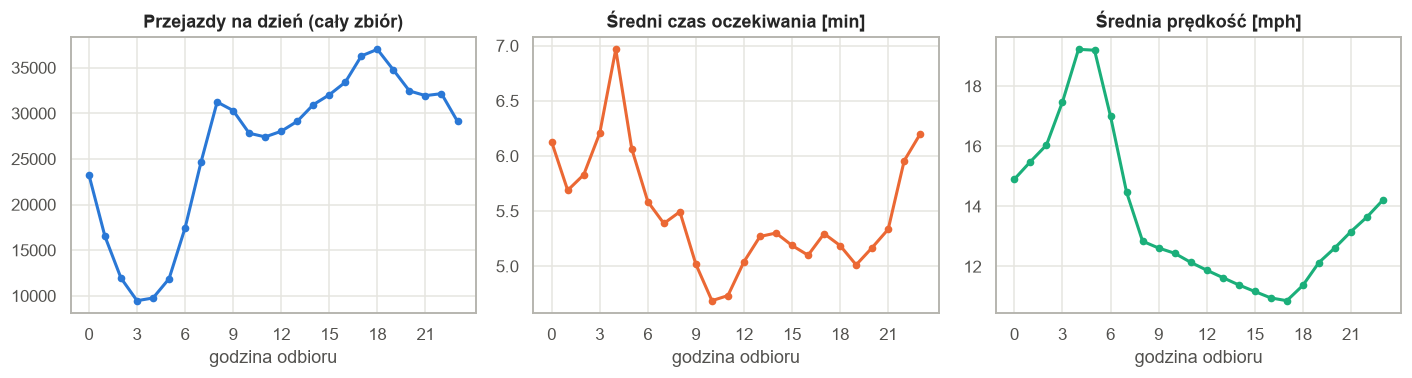

Spearman (natężenie vs prędkość), n = 168 godzin tygodnia: rho = -0.776, p = 5.38e-35
Spearman (natężenie vs czas oczekiwania): rho = -0.202, p = 8.59e-03


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
przejazdy_na_dzien,"23,250.85","16,508.53","11,941.52","9,465.00","9,759.82","11,873.78","17,442.84","24,689.42","31,238.68","30,300.77","27,816.05","27,416.24","28,033.77","29,125.53","30,944.21","32,030.21","33,413.45","36,286.64","37,011.69","34,752.34","32,450.44","31,940.15","32,154.54","29,115.99"
sr_oczekiwanie_min,6.13,5.69,5.83,6.21,6.97,6.06,5.59,5.39,5.49,5.02,4.69,4.73,5.04,5.27,5.30,5.19,5.10,5.29,5.19,5.01,5.17,5.33,5.96,6.20
sr_predkosc_mph,14.90,15.49,16.04,17.47,19.22,19.19,16.99,14.47,12.84,12.61,12.44,12.14,11.88,11.63,11.39,11.17,10.95,10.86,11.37,12.13,12.62,13.16,13.64,14.21


In [104]:
weighted = hourly.assign(
    wait_x_n=hourly["sr_oczekiwanie_min"] * hourly["przejazdy"],
    speed_x_n=hourly["sr_predkosc_mph"] * hourly["przejazdy"],
).groupby("hour")[["przejazdy", "wait_x_n", "speed_x_n"]].sum()
by_hour = pd.DataFrame({
    "przejazdy_na_dzien": weighted["przejazdy"] / report["sample_fraction"] / dow_days.sum(),
    "sr_oczekiwanie_min": weighted["wait_x_n"] / weighted["przejazdy"],
    "sr_predkosc_mph": weighted["speed_x_n"] / weighted["przejazdy"],
})

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, (col, title, color) in zip(axes, [
        ("przejazdy_na_dzien", "Przejazdy na dzień (cały zbiór)", SERIES[0]),
        ("sr_oczekiwanie_min", "Średni czas oczekiwania [min]", SERIES[1]),
        ("sr_predkosc_mph", "Średnia prędkość [mph]", SERIES[2])]):
    ax.plot(by_hour.index, by_hour[col], color=color, lw=2, marker="o", ms=4)
    ax.set_title(title)
    ax.set_xlabel("godzina odbioru")
    ax.set_xticks(range(0, 24, 3))
plt.tight_layout()
plt.show()

rho, p_val = stats.spearmanr(hourly["przejazdy_na_dzien"], hourly["sr_predkosc_mph"])
rho_w, p_w = stats.spearmanr(hourly["przejazdy_na_dzien"], hourly["sr_oczekiwanie_min"])
print(f"Spearman (natężenie vs prędkość), n = {len(hourly)} godzin tygodnia: rho = {rho:.3f}, p = {p_val:.2e}")
print(f"Spearman (natężenie vs czas oczekiwania): rho = {rho_w:.3f}, p = {p_w:.2e}")
by_hour.round(2).T

Na wykresach można zaobserwować, że najmniej przejazdów odbywa się około godziny 3, natomiast najwięcej o 18:00. Można zaobserwować, że średnia prędkosć jazdy spada wraz ze wzrostem przejazdów na dzień, taką sytuację moga powodować korki występujące w godzinach popołudniowych. Potwierdza to korelacja Spearmana, która wskazuje na silną ujemna zależność.

Czas oczekiwania na kierowcę jest najdłuższy w nocy i nad ranem, gdzie wynosi od 6 do 7 min, a najkrótszy przed południem około 4.5 minuty. Jego korelacja z natężeniem ruchu jest słaba, co oznacza, że liczba kierowców dostosowuje się do popytu, a w nocy po prostu jest ich mniej.

### 5.3. Od czego zależy cena przejazdu? Dystans i ceny w dzielnicach

In [105]:
boroughs = agg([
    {"$match": {"pu_borough": {"$nin": [None, "Unknown", "N/A"]}}},
    {"$group": {
        "_id": "$pu_borough",
        "przejazdy": {"$sum": 1},
        "oplata_pct": {"$percentile": {"input": "$base_passenger_fare", "p": [0.25, 0.5, 0.75], "method": "approximate"}},
        "cena_za_mile_pct": {"$percentile": {"input": "$fare_per_mile", "p": [0.25, 0.5, 0.75], "method": "approximate"}},
        "sr_dystans": {"$avg": "$trip_miles"},
        "udzial_lotnisko": {"$avg": {"$cond": ["$is_airport_trip", 1, 0]}},
        "udzial_oplata_cbd": {"$avg": {"$cond": [{"$gt": ["$cbd_congestion_fee", 0]}, 1, 0]}},
    }},
    {"$sort": {"przejazdy": -1}},
]).rename(columns={"_id": "dzielnica"}).set_index("dzielnica")
for col in ["oplata_pct", "cena_za_mile_pct"]:
    boroughs[[f"{col}_Q1", f"{col}_mediana", f"{col}_Q3"]] = pd.DataFrame(boroughs[col].tolist(), index=boroughs.index)
boroughs = boroughs.drop(columns=["oplata_pct", "cena_za_mile_pct"])
boroughs

,przejazdy,sr_dystans,udzial_lotnisko,udzial_oplata_cbd,oplata_pct_Q1,oplata_pct_mediana,oplata_pct_Q3,cena_za_mile_pct_Q1,cena_za_mile_pct_mediana,cena_za_mile_pct_Q3
dzielnica,,,,,,,,,,
Manhattan,2392922,4.34,0.07,0.76,14.52,22.20,34.62,5.33,7.75,11.35
Brooklyn,1963200,3.84,0.04,0.09,10.89,16.90,27.12,5.26,6.78,8.47
Queens,1582539,5.24,0.19,0.10,10.97,18.25,33.27,4.38,5.79,7.52
Bronx,936031,3.85,0.01,0.03,9.91,14.61,21.94,4.23,5.78,7.66
Staten Island,116329,4.51,0.02,0.02,9.34,14.66,23.86,4.22,5.38,6.77


Z tabeli można zaobserwować, że najwięcej przejazdów rozpoczyna się na Manhattanie, a najmniej na Staten Island. Biorąc pod uwagę medianę opłat, najtańsze przejazdy były w Bronksie oraz Staten Island wynoszące około 14.6 USD, natomiast najdroższe na Manhattanie wynoszące około 22.2 USD. Najdłuższe są średnio przejazdy z Queens, gdzie około 19% kursów to przejazdy z lub do lotniska. Dodatkowo około 76% kursów z Manhattanu objętych jest opłatą za wjazd do strefy CBD, podczas gdy w pozostałych dzielnicach jest to co najwyżej około 10%.

W celu sprawdzenia zależności pomiędzy dystansem a opłatą bazową wykorzystano współczynniki korelacji Pearsona oraz Spearmana, liczone na losowej próbce 200 tys. przejazdów.

Pearson r(dystans, opłata) = 0.822 (p = 0.0e+00)
Spearman rho(dystans, opłata) = 0.846 (p = 0.0e+00)


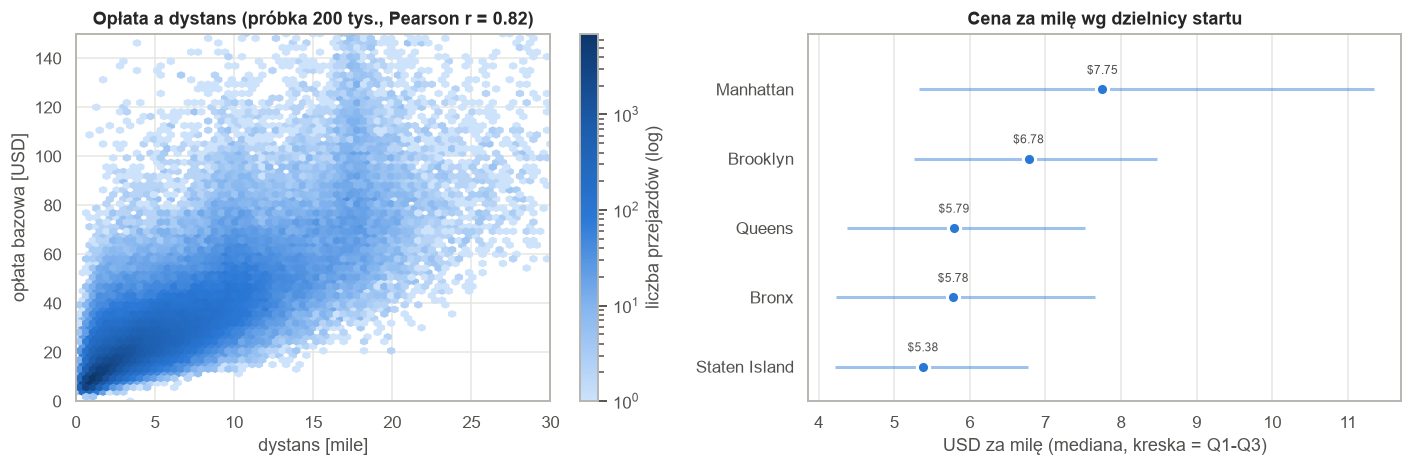

In [106]:
fares = sample_docs(200_000, None, ["trip_miles", "base_passenger_fare", "pu_borough"])
pearson_r, pearson_p = stats.pearsonr(fares["trip_miles"], fares["base_passenger_fare"])
spearman_r, spearman_p = stats.spearmanr(fares["trip_miles"], fares["base_passenger_fare"])
print(f"Pearson r(dystans, opłata) = {pearson_r:.3f} (p = {pearson_p:.1e})")
print(f"Spearman rho(dystans, opłata) = {spearman_r:.3f} (p = {spearman_p:.1e})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
hb = ax.hexbin(fares["trip_miles"], fares["base_passenger_fare"], gridsize=70, cmap=BLUES, mincnt=1,
               bins="log", extent=(0, 30, 0, 150))
ax.set_xlim(0, 30); ax.set_ylim(0, 150)
ax.set_xlabel("dystans [mile]"); ax.set_ylabel("opłata bazowa [USD]")
ax.set_title(f"Opłata a dystans (próbka 200 tys., Pearson r = {pearson_r:.2f})")
fig.colorbar(hb, ax=ax, label="liczba przejazdów (log)")

ax = axes[1]
b = boroughs.sort_values("cena_za_mile_pct_mediana")
yy = np.arange(len(b))
ax.hlines(yy, b["cena_za_mile_pct_Q1"], b["cena_za_mile_pct_Q3"], color=SERIES[0], lw=2, alpha=0.45)
ax.plot(b["cena_za_mile_pct_mediana"], yy, "o", color=SERIES[0], ms=8, markeredgecolor="white", markeredgewidth=2)
for i, v in enumerate(b["cena_za_mile_pct_mediana"]):
    ax.text(v, i + 0.22, f"${v:.2f}", ha="center", fontsize=8, color="#52514e")
ax.set_yticks(yy, b.index)
ax.set_ylim(-0.5, len(b) - 0.2)
ax.set_xlabel("USD za milę (mediana, kreska = Q1-Q3)")
ax.set_title("Cena za milę wg dzielnicy startu")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Współczynnik korelacji Pearsona wynosi r ≈ 0,82, a Spearmana ρ ≈ 0,84 (p-value < 0,001), co oznacza silną dodatnią zależność - co wskazuje, że im dalszy jest przejazd tym wyższa będzie opłata. Ważną obserwacją jest to, że punkty na wykresie są porozrzucane, co oznacza, że na tym samym dystansie ceny się różnią. Jest tak ponieważ nie tylko dystans, ale i inne czynniki jak mają wpływ na cenę przejazdu.

Na wykresie po prawej można zaobserwować, że najdroższa mila jest na Manhattanie z medianą około 7,75 USD. Występuje tam też największy rozrzut cen. Następnie w Brooklynie mediana wynosi około 6,78 USD. W Queens, Bronksie i na Staten Island mediana wynosi od około 5,40 do 5,80 USD za milę.

W celu sprawdzenia statystycznej istotności różnicy ceny za milę (`fare_per_mile`) pomiędzy dzielnicami wykorzystano test Kruskala-Wallisa wzbogacony o współczynnik ε² w celu określenia siły ewentualnego efektu.

In [107]:
fares["fare_per_mile"] = fares["base_passenger_fare"] / fares["trip_miles"]
groups = [g["fare_per_mile"].to_numpy() for name, g in fares.groupby("pu_borough")
          if len(g) > 100 and name not in ("Unknown", "N/A")]
h, p_kw = stats.kruskal(*groups)
eps2 = (h - len(groups) + 1) / (sum(map(len, groups)) - len(groups))
print(f"Kruskal-Wallis: H = {h:,.0f}, p = {p_kw:.1e}, epsilon² = {eps2:.3f} ({len(groups)} dzielnic)")

Kruskal-Wallis: H = 13,653, p = 0.0e+00, epsilon² = 0.068 (5 dzielnic)


Test Kruskala-Wallisa daje p-value ≈ 0, a więc jest mniejszy od przyjętego poziomu istotności α = 0,05, co pozwala na odrzucenie hipotezy zerowej - cena za milę różni się istotnie pomiędzy dzielnicami. Siła efektu jest jednak mała, bliska umiarkowanej (ε² ≈ 0,07).

### 5.4. Napiwki: kto i kiedy je daje?

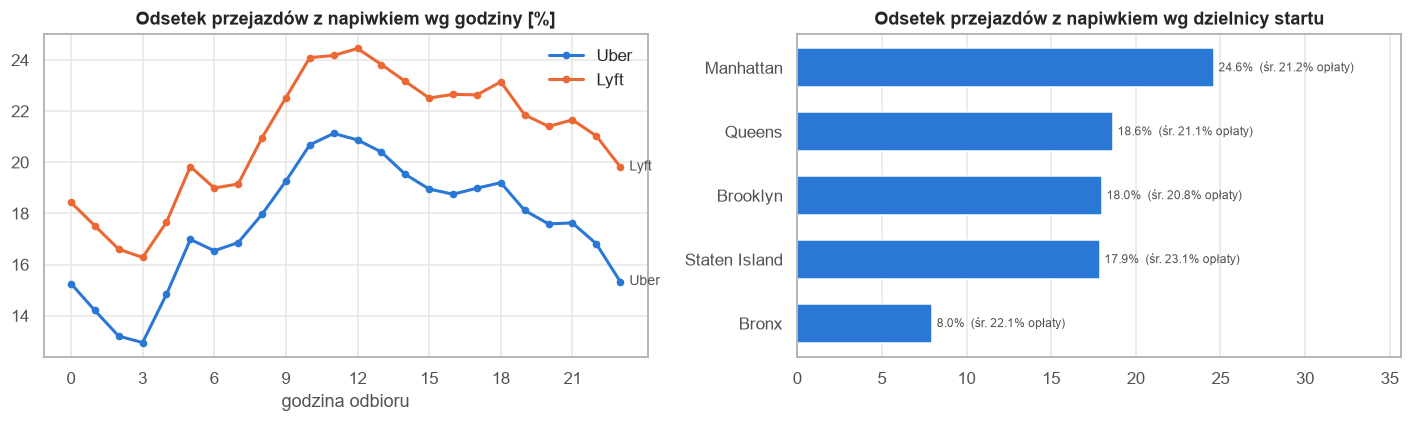

,przejazdy,odsetek_z_napiwkiem,sr_napiwek_usd,sr_napiwek_pct
dzielnica,,,,
Manhattan,2392922,24.61,6.19,21.20
Queens,1582539,18.65,6.35,21.09
Brooklyn,1963200,18.00,4.72,20.79
Staten Island,116329,17.87,4.70,23.14
Bronx,936031,7.97,4.20,22.10


In [108]:
tips_hour = agg([
    {"$group": {
        "_id": {"provider": "$provider", "hour": "$pickup_hour"},
        "przejazdy": {"$sum": 1},
        "z_napiwkiem": {"$sum": {"$cond": [{"$gt": ["$tips", 0]}, 1, 0]}},
        "sr_napiwek_pct": {"$avg": {"$cond": [{"$gt": ["$tips", 0]}, "$tip_pct", None]}},
    }},
])
tips_hour = pd.concat([pd.json_normalize(tips_hour["_id"]), tips_hour.drop(columns="_id")], axis=1)
tips_hour["odsetek_z_napiwkiem"] = tips_hour["z_napiwkiem"] / tips_hour["przejazdy"] * 100

tips_borough = agg([
    {"$match": {"pu_borough": {"$nin": [None, "Unknown", "N/A"]}}},
    {"$group": {
        "_id": "$pu_borough",
        "przejazdy": {"$sum": 1},
        "odsetek_z_napiwkiem": {"$avg": {"$cond": [{"$gt": ["$tips", 0]}, 100, 0]}},
        "sr_napiwek_usd": {"$avg": {"$cond": [{"$gt": ["$tips", 0]}, "$tips", None]}},
        "sr_napiwek_pct": {"$avg": {"$cond": [{"$gt": ["$tips", 0]}, "$tip_pct", None]}},
    }},
    {"$sort": {"odsetek_z_napiwkiem": -1}},
]).rename(columns={"_id": "dzielnica"}).set_index("dzielnica")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for prov in [p for p in ["Uber", "Lyft"] if p in set(tips_hour["provider"])]:
    d = tips_hour[tips_hour["provider"] == prov].sort_values("hour")
    axes[0].plot(d["hour"], d["odsetek_z_napiwkiem"], lw=2, marker="o", ms=4, color=PROVIDER_COLORS[prov], label=prov)
    axes[0].annotate(prov, (d["hour"].iloc[-1], d["odsetek_z_napiwkiem"].iloc[-1]), xytext=(6, 0),
                     textcoords="offset points", va="center", fontsize=9, color="#52514e")
axes[0].set_title("Odsetek przejazdów z napiwkiem wg godziny [%]")
axes[0].set_xlabel("godzina odbioru"); axes[0].set_xticks(range(0, 24, 3))
axes[0].legend(frameon=False)
tb = tips_borough.sort_values("odsetek_z_napiwkiem")
bars = axes[1].barh(tb.index, tb["odsetek_z_napiwkiem"], color=SERIES[0], height=0.6)
axes[1].bar_label(bars, labels=[f"{v:.1f}%  (śr. {s:.1f}% opłaty)" for v, s in
                                zip(tb["odsetek_z_napiwkiem"], tb["sr_napiwek_pct"])],
                  fontsize=8, color="#52514e", padding=3)
axes[1].set_title("Odsetek przejazdów z napiwkiem wg dzielnicy startu")
axes[1].set_xlim(right=tb["odsetek_z_napiwkiem"].max() * 1.45)
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
tips_borough

Na wykresie po lewej można zaobserwować, że pasażerowie Lyfta o każdej porze doby nieco częściej dają napiwki niż pasażerowie Ubera. Najwięcej napiwków jest w godzinach południowych a najmniej około 3:00 w nocy.

Na wykresie po prawej oraz w tabeli można zaobserwować duże różnice pomiędzy dzielnicami. Na Manhattanie napiwek pojawia się w około 25% kursów, natomiast w Bronksie tylko w około 8%. Ciekawą obserwacją jest fakt, że jeśli już napiwek się pojawi to mieści się w zakresie od około 20% do 23% ceny bazowej.

W celu sprawdzenia, czy kursy lotniskowe istotnie częściej kończą się napiwkiem niż pozostałe, wykorzystano test niezależności chi-kwadrat wzbogacony o współczynnik V Craméra w celu określenia siły ewentualnego związku.

In [109]:
ct = agg([
    {"$group": {"_id": {"lotnisko": "$is_airport_trip", "tip": {"$gt": ["$tips", 0]}}, "n": {"$sum": 1}}},
])
ct = (pd.concat([pd.json_normalize(ct["_id"]), ct["n"]], axis=1)
      .pivot(index="lotnisko", columns="tip", values="n").fillna(0))
ct.columns = ["bez napiwku", "z napiwkiem"]
ct.index = ct.index.map({False: "pozostałe kursy", True: "kursy lotniskowe"})
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
ct["% z napiwkiem"] = ct["z napiwkiem"] / ct.sum(axis=1) * 100
print(f"Chi² = {chi2:,.0f}, df = {dof}, p = {p:.1e}, V Craméra = {cramers_v:.3f}")
ct

Chi² = 63,634, df = 1, p = 0.0e+00, V Craméra = 0.095


,bez napiwku,z napiwkiem,% z napiwkiem
lotnisko,,,
pozostałe kursy,5271732,1153691,17.96
kursy lotniskowe,386308,179290,31.70


Z tabeli można zaobserwować, że kursy lotniskowe kończą się napiwkiem prawie dwa razy częściej niż pozostałe. Test chi-kwadrat daje p-value ≈ 0, a więc jest mniejszy od przyjętego poziomu istotności α = 0,05, co pozwala na odrzucenie hipotezy zerowej o niezależności. Siła związku jest słaba, jednak różnica jest wyraźnie widoczna.

### 5.5. Najpopularniejsze trasy między strefami

Przejazdy w obrębie jednej strefy: 8.3%


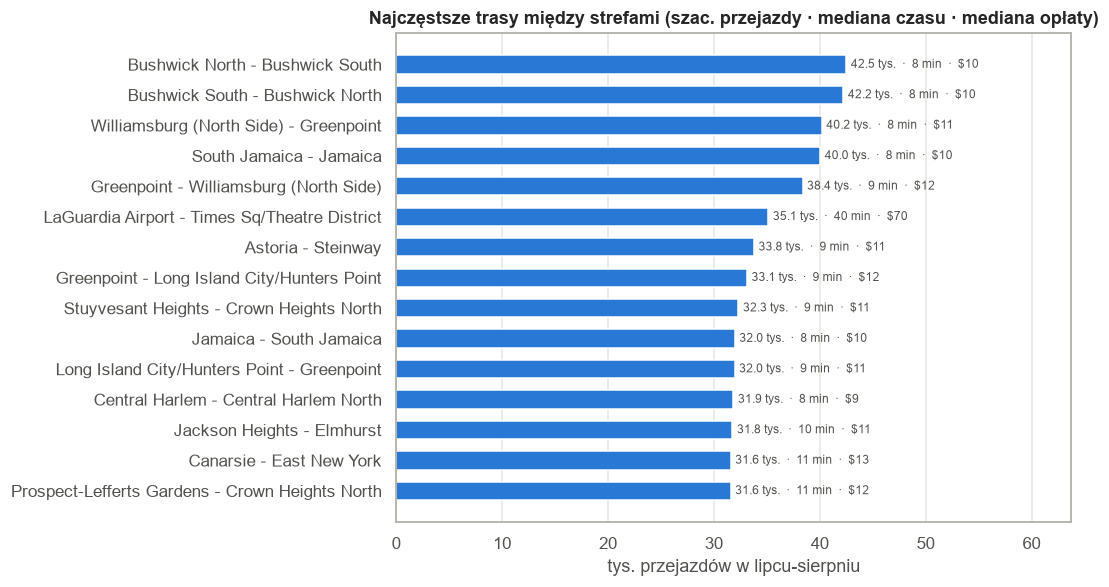

,trasa,przejazdy_szac,mediana_min,mediana_oplaty
0,Bushwick North - Bushwick South,"42,509.67",7.60,9.86
1,Bushwick South - Bushwick North,"42,230.78",7.54,9.85
2,Williamsburg (North Side) - Greenpoint,"40,189.24",8.23,11.46
3,South Jamaica - Jamaica,"40,038.64",7.93,9.84
4,Greenpoint - Williamsburg (North Side),"38,370.82",8.79,11.68
5,LaGuardia Airport - Times Sq/Theatre District,"35,141.18",40.41,70.22
6,Astoria - Steinway,"33,785.74",9.17,11.16
7,Greenpoint - Long Island City/Hunters Point,"33,127.54",9.25,11.66
8,Stuyvesant Heights - Crown Heights North,"32,318.73",9.14,11.00
9,Jamaica - South Jamaica,"31,972.90",8.42,10.10


In [110]:
same_zone = agg([
    {"$group": {"_id": None, "n": {"$sum": 1},
                "ta_sama_strefa": {"$sum": {"$cond": [{"$eq": ["$pu_location_id", "$do_location_id"]}, 1, 0]}}}},
]).iloc[0]
print(f"Przejazdy w obrębie jednej strefy: {same_zone['ta_sama_strefa'] / same_zone['n']:.1%}")

routes = agg([
    {"$match": {"$expr": {"$ne": ["$pu_location_id", "$do_location_id"]}}},
    {"$group": {
        "_id": {"z": "$pu_zone", "do": "$do_zone"},
        "przejazdy": {"$sum": 1},
        "mediana_min": {"$median": {"input": "$trip_minutes", "method": "approximate"}},
        "mediana_oplaty": {"$median": {"input": "$base_passenger_fare", "method": "approximate"}},
    }},
    {"$sort": {"przejazdy": -1}},
    {"$limit": 15},
])
routes = pd.concat([pd.json_normalize(routes["_id"]), routes.drop(columns="_id")], axis=1)
routes["trasa"] = routes["z"] + " - " + routes["do"]
routes["przejazdy_szac"] = routes["przejazdy"] / report["sample_fraction"]

fig, ax = plt.subplots(figsize=(10, 5.5))
r = routes.iloc[::-1]
bars = ax.barh(r["trasa"], r["przejazdy_szac"] / 1000, color=SERIES[0], height=0.6)
ax.bar_label(bars, labels=[f"{n / 1000:.1f} tys.  ·  {m:.0f} min  ·  ${f:.0f}" for n, m, f in
                           zip(r["przejazdy_szac"], r["mediana_min"], r["mediana_oplaty"])],
             fontsize=8, color="#52514e", padding=3)
ax.set_title("Najczęstsze trasy między strefami (szac. przejazdy · mediana czasu · mediana opłaty)")
ax.set_xlabel("tys. przejazdów w lipcu-sierpniu")
ax.set_xlim(right=r["przejazdy_szac"].max() / 1000 * 1.5)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
routes[["trasa", "przejazdy_szac", "mediana_min", "mediana_oplaty"]]

Około 8% kursów zaczyna się i kończy w tej samej strefie. Na wykresie można zaobserwować, że najpopularniejsze trasy to krótkie przejazdy około 8-11 minut i 9-13 USD pomiędzy sąsiednimi strefami poza Manhattanem, np. Bushwick North - Bushwick South, Williamsburg - Greenpoint czy Jamaica - South Jamaica. Wyjątkiem jest trasa LaGuardia Airport- Times Sq/Theatre District, która trwa około 40 minut i kosztuje około 70 USD, przez co jest jedną z droższych tras w podanym porównaniu.

## 6. Podsumowanie

Najważniejsze obserwacje:

1. Uber ma ok. 72% rynku. Kierowcy Ubera dostają większą część opłaty bazowej ok. 82% wobec 75% w Lyfcie, a za milę Lyft jest nieco droższy.
2. Popyt ma silny rytm dobowy i tygodniowy. W godzinach szczytu średnia prędkość spada niemal o połowę.
3. Cena silnie zależy od dystansu. Najdroższa mila jest na Manhattanie.
4. Napiwki daje mniej niż 1 na 5 pasażerów. Najczęściej dają je pasażerowie kursów lotniskowych i z Manhattanu.
5. Najczęstsze trasy to krótkie przejazdy między sąsiednimi strefami poza Manhattanem, a wyjątkiem jest LaGuardia - Times Square.

Ograniczenia:

Analizy działają na losowej próbce ok. 18% oczyszczonych przejazdów, dlatego liczby bezwzględne są przeskalowane na cały zbiór. Dane nie zawierają cen dynamicznych ani informacji o pasażerach. Przy bardzo dużych próbkach istotność statystyczna jest niemal pewna, więc interpretujemy przede wszystkim wielkość efektu.